In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns  #for data visualization


In [2]:
plt.style.use("ggplot")

In [6]:
df = pd.read_csv('job_email_dataset.csv')

In [7]:
df.head()

,subject,body,label,source_type
0,Your IBM Application,Ref: 110127BR - 2018 Data Scientist Internship...,rejection,real
1,Thank you from Workday!,"Hi Conor ,\n\nThank you for your interest in W...",rejection,real
2,An Update Regarding Your Visa Job Application,"\r\nDear Conor,\r\nThank you for giving us the...",rejection,real
3,Thank you for your interest in Zynga for Inter...,"Dear Conor,\n\nThank you for your interest in ...",rejection,real
4,Your Application with Cambia Health Solutions,"Dear Conor,\n\nThank you for the interest you ...",rejection,real


In [8]:
df.tail()

,subject,body,label,source_type
1195,A note from Silverbrook Energy recruiting,"Dear Alex,\n\nWe wanted to confirm that we hav...",application_received,synthetic
1196,Confirmation: Technical Writer,Your application for the Technical Writer posi...,application_received,synthetic
1197,Thank you for submitting your materials,The resume and application you submitted for M...,application_received,synthetic
1198,Application acknowledgment,Thank you for your interest in joining Oakshor...,application_received,synthetic
1199,We are reviewing your application,The team at Harborcrest Systems is reviewing y...,application_received,synthetic


In [9]:
df.shape()

TypeError: 'tuple' object is not callable

In [10]:
df.shape

(1200, 4)

In [11]:
df.dtypes

subject        str
body           str
label          str
source_type    str
dtype: object

In [12]:
df.drop(columns=["source_type"], inplace=True)

In [13]:
df.dtypes

subject    str
body       str
label      str
dtype: object

In [14]:
df.shape

(1200, 3)

In [17]:
df

,subject,body,label
0,Your IBM Application,Ref: 110127BR - 2018 Data Scientist Internship...,rejection
1,Thank you from Workday!,"Hi Conor ,\n\nThank you for your interest in W...",rejection
2,An Update Regarding Your Visa Job Application,"\r\nDear Conor,\r\nThank you for giving us the...",rejection
3,Thank you for your interest in Zynga for Inter...,"Dear Conor,\n\nThank you for your interest in ...",rejection
4,Your Application with Cambia Health Solutions,"Dear Conor,\n\nThank you for the interest you ...",rejection
...,...,...,...
1195,A note from Silverbrook Energy recruiting,"Dear Alex,\n\nWe wanted to confirm that we hav...",application_received
1196,Confirmation: Technical Writer,Your application for the Technical Writer posi...,application_received
1197,Thank you for submitting your materials,The resume and application you submitted for M...,application_received
1198,Application acknowledgment,Thank you for your interest in joining Oakshor...,application_received


In [18]:
df["label"].value_counts()

label
application_received    312
rejection               300
advancement             300
other                   288
Name: count, dtype: int64

In [19]:
df["label"].value_counts(normalize=True) * 100

label
application_received    26.0
rejection               25.0
advancement             25.0
other                   24.0
Name: proportion, dtype: float64

Text(0.5, 1.0, 'Email Label Distribution')

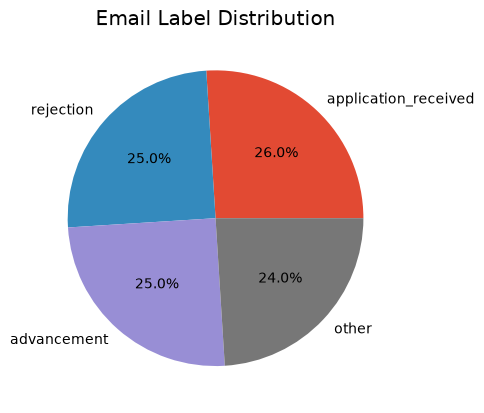

In [21]:
df["label"].value_counts().plot(
  kind="pie",
  autopct="%1.1f%%"
)
plt.ylabel("")
plt.title("Email Label Distribution")

In [22]:
df["Email Length"] = df['body'].apply(len)

In [23]:
df.head()

,subject,body,label,Email Length
0,Your IBM Application,Ref: 110127BR - 2018 Data Scientist Internship...,rejection,747
1,Thank you from Workday!,"Hi Conor ,\n\nThank you for your interest in W...",rejection,964
2,An Update Regarding Your Visa Job Application,"\r\nDear Conor,\r\nThank you for giving us the...",rejection,431
3,Thank you for your interest in Zynga for Inter...,"Dear Conor,\n\nThank you for your interest in ...",rejection,788
4,Your Application with Cambia Health Solutions,"Dear Conor,\n\nThank you for the interest you ...",rejection,1266


In [24]:
df['Email Length'].describe()

count    1200.000000
mean      275.345000
std       277.033874
min       106.000000
25%       182.750000
50%       239.000000
75%       279.000000
max      6196.000000
Name: Email Length, dtype: float64

In [25]:
df.groupby("label")["Email Length"].mean()

label
advancement             278.373333
application_received    236.868590
other                   157.986111
rejection               424.996667
Name: Email Length, dtype: float64

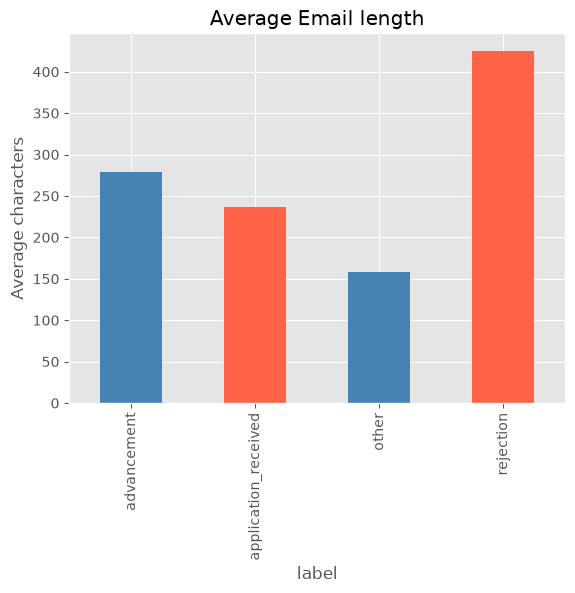

In [27]:
df.groupby("label")["Email Length"].mean().plot(
  kind="bar",
  color=["steelblue", "tomato"]
)
plt.ylabel("Average characters")
plt.title("Average Email length")
plt.show()

In [28]:
df.head()

,subject,body,label,Email Length
0,Your IBM Application,Ref: 110127BR - 2018 Data Scientist Internship...,rejection,747
1,Thank you from Workday!,"Hi Conor ,\n\nThank you for your interest in W...",rejection,964
2,An Update Regarding Your Visa Job Application,"\r\nDear Conor,\r\nThank you for giving us the...",rejection,431
3,Thank you for your interest in Zynga for Inter...,"Dear Conor,\n\nThank you for your interest in ...",rejection,788
4,Your Application with Cambia Health Solutions,"Dear Conor,\n\nThank you for the interest you ...",rejection,1266


In [29]:
df["Word Count"] = df["body"].apply(lambda x: len(x.split()))

In [30]:
df.head()

,subject,body,label,Email Length,Word Count
0,Your IBM Application,Ref: 110127BR - 2018 Data Scientist Internship...,rejection,747,120
1,Thank you from Workday!,"Hi Conor ,\n\nThank you for your interest in W...",rejection,964,161
2,An Update Regarding Your Visa Job Application,"\r\nDear Conor,\r\nThank you for giving us the...",rejection,431,64
3,Thank you for your interest in Zynga for Inter...,"Dear Conor,\n\nThank you for your interest in ...",rejection,788,131
4,Your Application with Cambia Health Solutions,"Dear Conor,\n\nThank you for the interest you ...",rejection,1266,146


In [31]:
df["label"] = df["label"].map({
  "rejection" : 0, 
  "advancement" : 1,
  "application_received" : 2,
  "other" : 3,
})

In [32]:
df.head()

,subject,body,label,Email Length,Word Count
0,Your IBM Application,Ref: 110127BR - 2018 Data Scientist Internship...,0,747,120
1,Thank you from Workday!,"Hi Conor ,\n\nThank you for your interest in W...",0,964,161
2,An Update Regarding Your Visa Job Application,"\r\nDear Conor,\r\nThank you for giving us the...",0,431,64
3,Thank you for your interest in Zynga for Inter...,"Dear Conor,\n\nThank you for your interest in ...",0,788,131
4,Your Application with Cambia Health Solutions,"Dear Conor,\n\nThank you for the interest you ...",0,1266,146


In [33]:
df

,subject,body,label,Email Length,Word Count
0,Your IBM Application,Ref: 110127BR - 2018 Data Scientist Internship...,0,747,120
1,Thank you from Workday!,"Hi Conor ,\n\nThank you for your interest in W...",0,964,161
2,An Update Regarding Your Visa Job Application,"\r\nDear Conor,\r\nThank you for giving us the...",0,431,64
3,Thank you for your interest in Zynga for Inter...,"Dear Conor,\n\nThank you for your interest in ...",0,788,131
4,Your Application with Cambia Health Solutions,"Dear Conor,\n\nThank you for the interest you ...",0,1266,146
...,...,...,...,...,...
1195,A note from Silverbrook Energy recruiting,"Dear Alex,\n\nWe wanted to confirm that we hav...",2,200,32
1196,Confirmation: Technical Writer,Your application for the Technical Writer posi...,2,228,34
1197,Thank you for submitting your materials,The resume and application you submitted for M...,2,226,36
1198,Application acknowledgment,Thank you for your interest in joining Oakshor...,2,245,36


In [34]:
import warnings
warnings.filterwarnings("ignore")


In [35]:
from sklearn.model_selection import train_test_split

In [36]:
x = df["body"]

In [37]:
y = df["label"]

In [38]:
x_train, x_test, y_train, y_test = train_test_split(
  x,
  y,
  test_size = 0.2,
  stratify=y
)

In [39]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
  stop_words = None,
  max_features = 5000,
  ngram_range = (1, 2)
)

In [40]:
x_train_tfidf = tfidf.fit_transform(x_train)

In [41]:
x_test_tfidf = tfidf.transform(x_test)

In [42]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.model_selection import RandomizedSearchCV

In [43]:
models = {
  "Naive Bayes":(
    MultinomialNB(),
      {
        "alpha": [0.1, 0.5, 1, 2, 5]
      }
  ),
  "LogisticRegression": (
    LogisticRegression(
      class_weight = "balanced",
      max_iter = 1000
    ),
    {
      "C": [0.01, 0.1, 1, 10, 100]
    }
  ), 
  "Linear SVM": (
    LinearSVC(
      class_weight = "balanced",
    ),
    {
      "C": [0.01, 0.1, 1, 10]
    }
  ),
  "Random Forest": (
    RandomForestClassifier(
      class_weight = "balanced"
    ), 
    {
      "n_estimators" : [100, 200, 300],
      "max_depth": [10, 20, None],
      "min_samples_split": [2, 5, 10]
    }
  ), 
  "Decision Tree": (
    DecisionTreeClassifier(
      class_weight = "balanced"
    ),
    {
      "max_depth": [5, 10, 20, None],
      "min_samples_split": [2, 5, 10]
    }
  ),
  "Gradient Boosting" : (
    GradientBoostingClassifier(),
    {
      "n_estimators": [100, 200],
      "learning_rate": [0.01, 0.05, 0.1],
      "max_depth": [3, 5]
    }
  ),
  "KNN": (
    KNeighborsClassifier(),
    {
      "n_neighbors" : [3, 5, 7, 9]
    }
  )
}

In [45]:
results = []
best_models = {}

for name, (model, params) in models.items():
    search = RandomizedSearchCV(
        estimator=model,
        param_distributions=params,
        n_iter=10,
        cv=5,
        scoring="f1_macro",
        n_jobs=-1,
        random_state=42,
        error_score="raise"
    )

    search.fit(x_train_tfidf, y_train)

    best_model = search.best_estimator_
    best_models[name] = best_model

    predictions = best_model.predict(x_test_tfidf)

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(
        y_test, predictions, average="macro", zero_division=0
    )
    recall = recall_score(
        y_test, predictions, average="macro", zero_division=0
    )
    f1 = f1_score(
        y_test, predictions, average="macro", zero_division=0
    )

    auc = np.nan

    if hasattr(best_model, "predict_proba"):
        probabilities = best_model.predict_proba(x_test_tfidf)

        auc = roc_auc_score(
            y_test,
            probabilities,
            labels=best_model.classes_,
            multi_class="ovr",
            average="macro"
        )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC AUC": auc,
        "Best Params": search.best_params_
    })

In [46]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
  by = ["F1 Score", "ROC AUC"],
  ascending = False
)

In [47]:
results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Best Params
1,LogisticRegression,1.000000,1.000000,1.000000,1.000000,1.000000,{'C': 100}
2,Linear SVM,1.000000,1.000000,1.000000,1.000000,NaN,{'C': 10}
3,Random Forest,0.991667,0.991801,0.991801,0.991801,0.999955,"{'n_estimators': 100, 'min_samples_split': 10,..."
0,Naive Bayes,0.991667,0.991803,0.991657,0.991661,1.000000,{'alpha': 0.5}
6,KNN,0.991667,0.991803,0.991657,0.991661,0.997984,{'n_neighbors': 3}
5,Gradient Boosting,0.987500,0.987897,0.987491,0.987659,0.999838,"{'n_estimators': 200, 'max_depth': 3, 'learnin..."
4,Decision Tree,0.958333,0.958429,0.958315,0.958271,0.972212,"{'min_samples_split': 2, 'max_depth': None}"


In [48]:
results_df.style.background_gradient(
  cmap = "Greens",
  subset = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC AUC"]
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Best Params
1,LogisticRegression,1.000000,1.000000,1.000000,1.000000,1.000000,{'C': 100}
2,Linear SVM,1.000000,1.000000,1.000000,1.000000,nan,{'C': 10}
3,Random Forest,0.991667,0.991801,0.991801,0.991801,0.999955,"{'n_estimators': 100, 'min_samples_split': 10, 'max_depth': None}"
0,Naive Bayes,0.991667,0.991803,0.991657,0.991661,1.000000,{'alpha': 0.5}
6,KNN,0.991667,0.991803,0.991657,0.991661,0.997984,{'n_neighbors': 3}
5,Gradient Boosting,0.987500,0.987897,0.987491,0.987659,0.999838,"{'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.1}"
4,Decision Tree,0.958333,0.958429,0.958315,0.958271,0.972212,"{'min_samples_split': 2, 'max_depth': None}"


In [49]:
best_model_name = results_df.iloc[0]["Model"]

In [50]:
best_model_name

'LogisticRegression'

In [51]:
best_model

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](4,)","[0,1,2,3]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


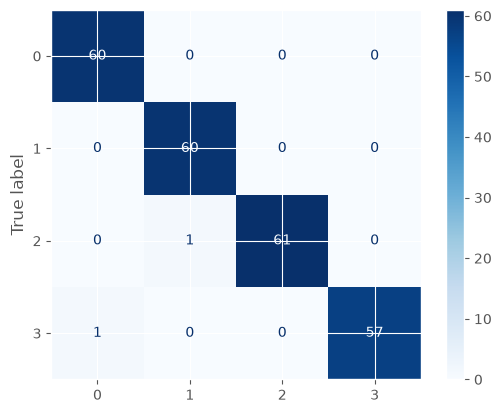

In [52]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
  best_model,
  x_test_tfidf,
  y_test,
  cmap = "Blues"
)

plt.xlabel("")
plt.show()

In [53]:
emails = [
  "Thank you for applying to Fall Software Development Engineer Internship - 2026 (US) position (Job ID: 3116030). We would like to invite you to complete the first step in our recruiting process; the online assessment (OA)!",
  
  "Thank you for applying to the Fall Software Development Engineer Internship - 2026 (US) position. We have received your application, please wait for further notice!",
  
  "Thank you for applying to the Fall Software Development Engineer Internship - 2026 (US) position. Unfortunately, we have decided to pursue other applicants at this time. We have your information on file, if you see another posting at this company please don't hesitate to apply!",
  
  "Your receipt at canes: $18.60 for a caniac combo no slaw xtra fries"
]

In [55]:
# Example only—adjust to match your encoding.
label_names = {
    0: "rejection",
    1: "advancement",
    2: "application_received",
    3: "other"
}

emails_vectorized = tfidf.transform(emails)
model = best_model
predictions = model.predict(emails_vectorized)

for email, prediction in zip(emails, predictions):
    print(f"Email: {email}")
    print(f"Prediction: {label_names[prediction]}")
    print("-" * 80)

Email: Thank you for applying to Fall Software Development Engineer Internship - 2026 (US) position (Job ID: 3116030). We would like to invite you to complete the first step in our recruiting process; the online assessment (OA)!
Prediction: advancement
--------------------------------------------------------------------------------
Email: Thank you for applying to the Fall Software Development Engineer Internship - 2026 (US) position. We have received your application, please wait for further notice!
Prediction: application_received
--------------------------------------------------------------------------------
Email: Thank you for applying to the Fall Software Development Engineer Internship - 2026 (US) position. Unfortunately, we have decided to pursue other applicants at this time. We have your information on file, if you see another posting at this company please don't hesitate to apply!
Prediction: rejection
------------------------------------------------------------------------

In [59]:
test_df = pd.read_csv("email_test_set_80.csv").fillna("")

label_names = {
    0: "rejection",
    1: "advancement",
    2: "application_received",
    3: "other"
}

# Use the same input format you used during training.
emails = test_df["subject"] + "\n" + test_df["body"]
# If you trained on body only, use:
# emails = test_df["body"]

emails_vectorized = tfidf.transform(emails)

model = best_model
predictions = model.predict(emails_vectorized)

test_df["predicted_label"] = [
    label_names[prediction] for prediction in predictions
]
test_df["correct"] = test_df["label"] == test_df["predicted_label"]

print("Accuracy:", accuracy_score(
    test_df["label"], test_df["predicted_label"]
))

print(classification_report(
    test_df["label"],
    test_df["predicted_label"],
    zero_division=0
))

# Show any incorrect predictions.
display(test_df.loc[
    ~test_df["correct"],
    ["body", "label", "predicted_label", "source_type"]
])

# Save all predictions.
test_df.to_csv("email_test_results.csv", index=False)

Accuracy: 0.8
                      precision    recall  f1-score   support

         advancement       0.94      0.85      0.89        20
application_received       0.76      0.80      0.78        20
               other       1.00      0.65      0.79        20
           rejection       0.64      0.90      0.75        20

            accuracy                           0.80        80
           macro avg       0.84      0.80      0.80        80
        weighted avg       0.84      0.80      0.80        80



,body,label,predicted_label,source_type
0,The panel approved moving your Embedded Softwa...,advancement,rejection,synthetic
4,"Hi Dakota, the lease renewal from Mossbrook is...",other,application_received,synthetic
13,We regret that Kestrel Harbor cannot approve y...,other,rejection,synthetic
14,"Hi Lee, the lease renewal from Flint Cove is r...",other,application_received,synthetic
17,The Research Coordinator opening at Kestrel Ha...,rejection,application_received,synthetic
18,"Hi Arden, we can confirm your Platform Enginee...",application_received,rejection,synthetic
34,"Hi Toby, we can confirm your Support Engineer ...",application_received,rejection,synthetic
41,We regret that Laurel Rise cannot approve your...,other,rejection,synthetic
43,"Hi Jess, we can confirm your Finance Associate...",application_received,rejection,synthetic
44,We regret that Ashwater cannot approve your pe...,other,rejection,synthetic


In [58]:
from sklearn.metrics import accuracy_score, classification_report

In [60]:
test_df = pd.read_csv("email_test_set_80.csv").fillna("")

label_names = {
    0: "rejection",
    1: "advancement",
    2: "application_received",
    3: "other"
}

# Use the same input format you used during training.
emails = test_df["subject"] + "\n" + test_df["body"]
# If you trained on body only, use:
# emails = test_df["body"]

emails_vectorized = tfidf.transform(emails)

model = best_model
predictions = model.predict(emails_vectorized)

test_df["predicted_label"] = [
    label_names[prediction] for prediction in predictions
]
test_df["correct"] = test_df["label"] == test_df["predicted_label"]

print("Accuracy:", accuracy_score(
    test_df["label"], test_df["predicted_label"]
))

print(classification_report(
    test_df["label"],
    test_df["predicted_label"],
    zero_division=0
))

# Show any incorrect predictions.
display(test_df.loc[
    ~test_df["correct"],
    ["body", "label", "predicted_label", "source_type"]
])

# Save all predictions.
test_df.to_csv("email_test_results.csv", index=False)

Accuracy: 0.8
                      precision    recall  f1-score   support

         advancement       0.94      0.85      0.89        20
application_received       0.76      0.80      0.78        20
               other       1.00      0.65      0.79        20
           rejection       0.64      0.90      0.75        20

            accuracy                           0.80        80
           macro avg       0.84      0.80      0.80        80
        weighted avg       0.84      0.80      0.80        80



,body,label,predicted_label,source_type
0,The panel approved moving your Embedded Softwa...,advancement,rejection,synthetic
4,"Hi Dakota, the lease renewal from Mossbrook is...",other,application_received,synthetic
13,We regret that Kestrel Harbor cannot approve y...,other,rejection,synthetic
14,"Hi Lee, the lease renewal from Flint Cove is r...",other,application_received,synthetic
17,The Research Coordinator opening at Kestrel Ha...,rejection,application_received,synthetic
18,"Hi Arden, we can confirm your Platform Enginee...",application_received,rejection,synthetic
34,"Hi Toby, we can confirm your Support Engineer ...",application_received,rejection,synthetic
41,We regret that Laurel Rise cannot approve your...,other,rejection,synthetic
43,"Hi Jess, we can confirm your Finance Associate...",application_received,rejection,synthetic
44,We regret that Ashwater cannot approve your pe...,other,rejection,synthetic


In [61]:
for _, row in test_df.loc[~test_df["correct"]].iterrows():
    print("Expected:", row["label"])
    print("Predicted:", row["predicted_label"])
    print("Email:", row["body"])
    print("-" * 80)

Expected: advancement
Predicted: rejection
Email: The panel approved moving your Embedded Software Intern application at Alder Point into the final interview stage. Our coordinator will send available slots shortly. Please keep an eye on your inbox.
--------------------------------------------------------------------------------
Expected: other
Predicted: application_received
Email: Hi Dakota, the lease renewal from Mossbrook is ready for review and signature. Please sign in to the resident portal. This document concerns your apartment tenancy.
--------------------------------------------------------------------------------
Expected: other
Predicted: rejection
Email: We regret that Kestrel Harbor cannot approve your personal loan application. You can review the reasons in your account. This decision concerns financing, not employment.
--------------------------------------------------------------------------------
Expected: other
Predicted: application_received
Email: Hi Lee, the lease